In [1]:
# This is official UI for camera trap species identification 
# This gives us real time species identification using trained RGB+Depth fusion model 
# Working and structure :--
# This UI works on an Flask API runs locally on this machine. 
# Tasks  -- It loads Depth v2 , generates a depth map from uploaded RGB image 
# Then the already trained ResNet 50 model predicts species 
# This how it turns this dessertation from something output result to a live demo 




In [2]:
# Import section wheee we get some modules for working :--
from flask import Flask , request , jsonify 
# Flask :-- creates an backend servere for web app
# request :-- used for api fetcjing and  user data 
# jsonify :-- used for conversiin of python data reeceivd to JSON format for users 
from flask_cors import CORS
# CORS stands for Cross-Origin Resource Sharing 
# It allows frontend webpage to run on other port or domain to get communication with flask server 
import torch 
import torch.nn as nn
import torchvision.models as models # Gets the pre-trained model for working 
from torchvision import transforms # Performs image preprocessing whicb we did same in models 
from transformers import pipeline
from PIL import Image # Used to open and process image 
import numpy as nup
import io # io insted of os because image is uploading thriugh a web request 
import base64 # Decodes binary data into Base64 text
print("All libereries installed succesfully ")


All libereries installed succesfully 


In [3]:
# Adding the path of ResNet50 only as for comparision 
# Path for trained RGB-only ResNet50 model :--
resnet_path = "D:\\Camera_trap\\resnet50_trained.pth"

# Normalization values for RGB-only model (3 channels, no depth) :--
resnet_mean = [0.485, 0.456, 0.406]
resnet_deviation = [0.229, 0.224, 0.225]

resnet_normalize = transforms.Normalize(
    resnet_mean,
    resnet_deviation
)

print("RGB-only model path and normalization ready")

RGB-only model path and normalization ready


In [4]:
# Lets choose device and model for working 
if torch.cuda.is_available():
    SYSTEM = "cuda"
else :
    SYSTEM = "cpu"
# Device selected :;--
print("Performing Device",SYSTEM)
# Path for trained fusion model :--
fusion_path = "D:\\Camera_trap\\models\\fusion_resnet50_trained.pth"
# Total number of animal classes which we need to undego with 
total_classes = 13
orignal_category = [
    1,3,5,6,7,8,9,10,11,16,34,51,99
]

# Now we need to store class_name using real species names :--
class_name = [
    "opossum",   # 1
    "raccoon",   # 3
    "squirrel",  # 5
    "bobcat",    # 6
    "skunk",     # 7
    "dog",       # 8
    "coyote",    # 9
    "rabbit",    # 10
    "bird",      # 11
    "cat",       # 16
    "deer",      # 34
    "fox",       # 51
    "rodent",    # 99
]
# All values stored sucessfully:--
print("Model path")
print(fusion_path)
print("Total classes")
print(total_classes)
print("categories_ids")
print(orignal_category)
print("Classes_names")
print(class_name)


Performing Device cuda
Model path
D:\Camera_trap\models\fusion_resnet50_trained.pth
Total classes
13
categories_ids
[1, 3, 5, 6, 7, 8, 9, 10, 11, 16, 34, 51, 99]
Classes_names
['opossum', 'raccoon', 'squirrel', 'bobcat', 'skunk', 'dog', 'coyote', 'rabbit', 'bird', 'cat', 'deer', 'fox', 'rodent']


In [5]:
# Now we need to built our resnet 50 classification model for identifying
def resnet50_working_model(total_classes):
    # Forming an resnet50 model architechture
    model = models.resnet50(weights=None)  # Initially taken with none
    # We need to change the previous layer of model to our required one
    previous_layer = model.conv1  # Old convolution layer
    latest_layer = nn.Conv2d(
        in_channels=4,
        out_channels=previous_layer.out_channels,
        kernel_size=previous_layer.kernel_size,
        stride=previous_layer.stride,
        padding=previous_layer.padding,
        bias=False
    )  
    # New convolution layer with 4 input channels
    # Now we will take all other as it is from old layer
    model.conv1 = latest_layer
    model.fc = nn.Linear(
        in_features=model.fc.in_features,
        out_features=total_classes
    )
    return model

print("Model is ready to implement")

Model is ready to implement


In [10]:
# Path for trained bbox-cropped ResNet50 model :--
resnet_bbox_path = "D:\\Camera_trap\\models\\resnet50_bbox_cropped_trained.pth"

# Loading the bbox-cropped model (same 3-channel architecture as RGB-only) :--
resnet_bbox_model = resnet50_rgb_only(total_classes)

resnet_bbox_state_info = torch.load(
    resnet_bbox_path,
    map_location=SYSTEM
)

resnet_bbox_model.load_state_dict(resnet_bbox_state_info)
resnet_bbox_model.to(SYSTEM)
resnet_bbox_model.eval()

print("Bbox-cropped ResNet50 model loaded and ready")

D:\Temp\ipykernel_13136\2018392306.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  resnet_bbox_state_info = torch.load(


Bbox-cropped ResNet50 model loaded and ready


In [7]:
# Loading orignal RedNet50 and orignal weights 
# Now we build and load the RGB-only ResNet50 model (no depth) :--
def resnet50_rgb_only(total_classes):
    model = models.resnet50(weights=None)
    model.fc = nn.Linear(
        in_features=model.fc.in_features,
        out_features=total_classes
    )
    return model

resnet_only_model = resnet50_rgb_only(total_classes)

resnet_state_info = torch.load(
    resnet_path,
    map_location=SYSTEM
)

resnet_only_model.load_state_dict(resnet_state_info)
resnet_only_model.to(SYSTEM)
resnet_only_model.eval()

print("RGB-only ResNet50 model loaded and ready")

D:\Temp\ipykernel_13136\1520515805.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  resnet_state_info = torch.load(


RGB-only ResNet50 model loaded and ready


In [8]:
# Calling and creating the Fusion ResNet-50 model.
# The total number of classes in the dataset is passed as a parameter.
working_model = resnet50_working_model(total_classes)

# Load the saved checkpoint file from the specified path.
# map_location ensures the model is loaded onto the selected device.
state_info = torch.load(
    fusion_path,
    map_location=SYSTEM
)

# Load the trained weights into the model.
working_model.load_state_dict(state_info)

# Move the complete model to the selected device (GPU or CPU).
working_model.to(SYSTEM)

# Set the model to evaluation mode.
# This disables training behaviour such as Dropout
# and makes Batch Normalization use the learned statistics.
working_model.eval()

# Display a confirmation message.
print("Model loaded and ready")

D:\Temp\ipykernel_13136\1048333416.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_info = torch.load(


Model loaded and ready


In [9]:
# Now let's load the pre-trained Depth Anything V2 model.
# This model is used to estimate a depth map from an RGB image.

# Select the processing device.
# If CUDA is available, use the first GPU.
# Otherwise, use the CPU.
if SYSTEM == "cuda":
    device = 0
else:
    device = -1

# Create the depth estimation pipeline.
pipeline_depth = pipeline(

    # Specify the task to be performed.
    # The pipeline will generate a depth map from an RGB image.
    task="depth-estimation",

    # Load the pre-trained Depth Anything V2 Base model.
    model="depth-anything/Depth-Anything-V2-Base-hf",

    # Pass the selected device to the pipeline.
    device=device
)

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

In [11]:
# Transformation

# Same normalization values used while training the model.

# Mean values for the four channels.
# These represent the average pixel value of each channel.
working_model_mean = [
    0.485,  # Red
    0.456,  # Green
    0.406,  # Blue
    0.500   # Depth
]

# Standard deviation values for the four channels.
# These values are used to scale each channel after
# subtracting its corresponding mean.
working_model_deviation = [
    0.229,  # Red
    0.224,  # Green
    0.225,  # Blue
    0.225   # Depth
]

# Create the normalization transform.
# Every fused image (RGB + Depth) will pass through
# this transformation before being given to the model.
working_model_fusion = transforms.Normalize(
    working_model_mean,
    working_model_deviation
)

# Display a confirmation message.
print("Normalization done")

Normalization done


In [12]:
# Preprocessing function for RGB-only model (no depth needed) :--
def image_pre_processing_rgb(image):
    rgb_updated = image.resize((224, 224))
    image_converted = nup.array(rgb_updated)
    image_array = image_converted.astype(nup.float32) / 255.0

    tensor_image = torch.from_numpy(image_array)
    tensor_image = tensor_image.permute(2, 0, 1)
    tensor_image = tensor_image.float()

    tensor_image = resnet_normalize(tensor_image)
    tensor_image = tensor_image.unsqueeze(0)

    return tensor_image

print("RGB-only pre-processing function ready")

RGB-only pre-processing function ready


In [13]:
# Now we will write the function to process an test rgb image 
# Procesws is simeple it generates the depth map combines RGB and Depth 
def image_pre_processing(image):
    # RGB IMAGE :--
    # We will take an rgb image 
    rgb_updated = image.resize((224,224))
    #Lets convert image into numpy:--
    image_converted = nup.array(rgb_updated)
    image_array = image_converted.astype(nup.float32)/255.0
    # Hence we got our RGB image 
    
    # DEPTH IMAGE :--
    depth_image = pipeline_depth(image)
    depth_img = depth_image["depth"] # Extract generated depth image 
    # Same process of resixing :--
    depth_img = depth_img.resize((224,224))
    # Convert depth image into numpy array:--
    depth_img_array = nup.array(depth_img).astype(nup.uint8)
    depth_img_array_raw = depth_img_array.astype(nup.float32)
    # Scale the depth values from 0-255 to 0-1
    depth_img_array_raw = depth_img_array_raw / 255.0
    final_depth = depth_img_array_raw

    # FUSION :-- 
    # Expand depth image from one channel --
    depth_channel = nup.expand_dims(final_depth,axis = -1)
    # Combineing RGB IMAGE AND DEPTH IMAGE 
    final_image = nup.concatenate(
        [image_array,depth_channel],
        axis = -1
    )

    # CONVERT TO TENSOR FOR MACHINE LEARNING :--
    # Convert numpy array image to pythorch tensor :--
    tensor_image = torch.from_numpy(final_image)
    tensor_image = tensor_image.permute(2,0,1)
    tensor_image = tensor_image.float()

    # NORMALIZATION:--
    tensor_image = working_model_fusion(tensor_image)

    # BATCH DIMENSION:--
    # Add one extra dimension bexause pytorch expects batches of images 
    tensor_image = tensor_image.unsqueeze(0)

    print("Pre_processing done ")

    return tensor_image , depth_img_array
print("Pre_processing done ")

Pre_processing done 


Pre_processing done 
Fusion tensor shape : torch.Size([1, 4, 224, 224])
Depth image shape : (224, 224)
Depth value range : 2 - 253


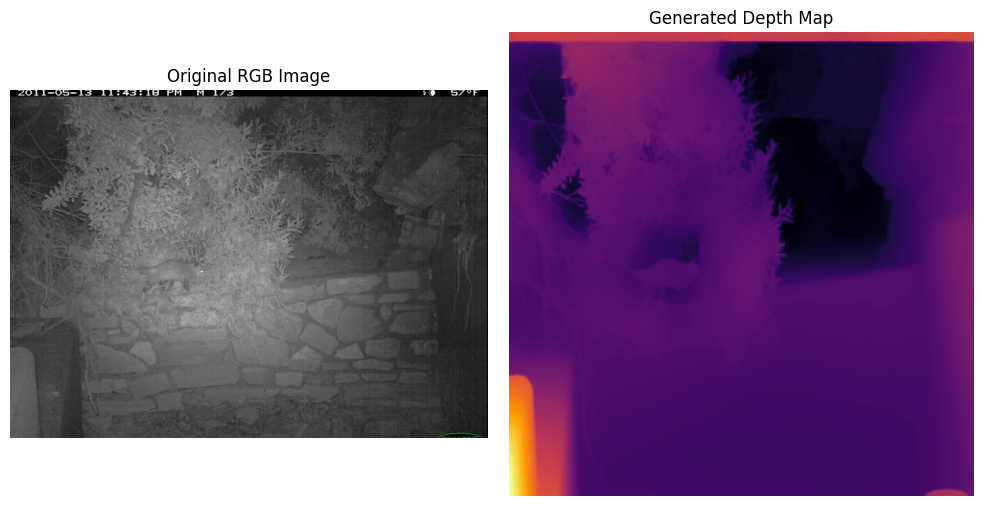

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

# Now we will test our complete preprocessing function.
# We will load one RGB image from the dataset,
# generate its depth map and display both images.

# Path of the sample image from the dataset.
test_image_path = (
    r"D:\Camera_trap\data\raw_data\eccv_18_all_images_sm"
    r"\5998cfa4-23d2-11e8-a6a3-ec086b02610b.jpg"
)

# Open the selected image.
# Convert it into RGB format because the model
# expects a three-channel colour image.
test_image = Image.open(test_image_path).convert("RGB")

# Pass the image through the preprocessing function.
# It returns:
# 1. The fused tensor (RGB + Depth)
# 2. The generated depth image
fusion_tensor, generated_depth = image_pre_processing(test_image)

# Display the shape of the fused tensor.
# Expected output:
# Batch Size = 1
# Channels = 4
# Height = 224
# Width = 224
print("Fusion tensor shape :", fusion_tensor.shape)

# Display the shape of the generated depth image.
print("Depth image shape :", generated_depth.shape)

# Display the minimum and maximum values
# present in the depth image.
print(
    "Depth value range :",
    generated_depth.min(),
    "-",
    generated_depth.max()
)

# VISUALIZATION :--

# Create one row and two columns.
# The first plot shows the RGB image.
# The second plot shows the generated depth map.
figure, axis = plt.subplots(
    1,
    2,
    figsize=(10,5)
)

# Display the original RGB image.
axis[0].imshow(test_image)
axis[0].set_title("Original RGB Image")
axis[0].axis("off")

# Display the generated depth map.
axis[1].imshow(
    generated_depth,
    cmap="inferno"
)
axis[1].set_title("Generated Depth Map")
axis[1].axis("off")

# Adjust the spacing between both images.
plt.tight_layout()

# Display both images on the screen.
plt.show()

In [15]:
import io
import base64

# Now we will create a function to convert the generated
# depth image into a Base64 string.
# The browser cannot directly display a NumPy array,
# so we convert it into a PNG image and then encode it.

def depth_array_to_base64(depth_array_raw):

    # Convert the NumPy depth array into a grayscale image.
    # "L" represents an 8-bit grayscale image.
    depth_image = Image.fromarray(depth_array_raw).convert("L")

    # Create an empty memory buffer.
    # The PNG image will be stored here temporarily.
    image_buffer = io.BytesIO()

    # Save the depth image inside the memory buffer
    # in PNG format.
    depth_image.save(
        image_buffer,
        format="PNG"
    )

    # Convert the PNG image into Base64 format.
    # Decode it into a normal string.
    encoded_image = base64.b64encode(
        image_buffer.getvalue()
    ).decode("utf-8")

    # Return the Base64 string with the image header.
    # This format allows browsers to display the image directly.
    return f"data:image/png;base64,{encoded_image}"


# TESTING :--

# Convert the generated depth image into Base64 format.
test_base64 = depth_array_to_base64(generated_depth)

# Display the total length of the Base64 string.
print("Base64 string length :", len(test_base64))

# Display the first few characters of the Base64 string.
# This confirms that the conversion was successful.
print("Starts with :", test_base64[:50])





Base64 string length : 18342
Starts with : data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAOAA


In [16]:
# Flask app real live :--
from flask import Flask, request, jsonify
from flask_cors import CORS
# Create the Flask application.
app = Flask(__name__)
# Enable Cross-Origin Resource Sharing.
# This allows the frontend webpage to communicate
# with the Flask backend.
CORS(app)
# PREDICTION API :--
# Create the prediction route.
# This route accepts only POST requests.
@app.route("/predict", methods=["POST"])
def predict():
    # Check whether an image has been uploaded.
    if "image" not in request.files:
        return jsonify(
            {"error": "No image uploaded"}
        ), 400
    # Read the uploaded image.
    file = request.files["image"]
    # Check which model was requested by the frontend :--
    # Defaults to "fusion" if nothing was sent
    selected_model = request.form.get("model", "fusion")
    # Try to open the uploaded image.
    try:
        image = Image.open(file.stream).convert("RGB")
    # If the image cannot be opened,
    # return an error message.
    except Exception as error:
        return jsonify(
            {"error": f"Could not read image : {error}"}
        ), 400
    # MODEL BRANCH :--
    if selected_model == "resnet50":
        # RGB-ONLY PATH :--
        tensor_image = image_pre_processing_rgb(image)
        tensor_image = tensor_image.to(SYSTEM)
        with torch.no_grad():
            output = resnet_only_model(tensor_image)
            probability = torch.softmax(output, dim=1)[0]
            top3_confidence, top3_index = torch.topk(probability, 3)
        depth_base64 = None
    elif selected_model == "resnet50_bbox":
        # BBOX-CROPPED PATH (new experiment) :--
        # Same 3-channel architecture and preprocessing as RGB-only,
        # but loaded with weights trained on bbox-cropped images.
        tensor_image = image_pre_processing_rgb(image)
        tensor_image = tensor_image.to(SYSTEM)
        with torch.no_grad():
            output = resnet_bbox_model(tensor_image)
            probability = torch.softmax(output, dim=1)[0]
            top3_confidence, top3_index = torch.topk(probability, 3)
        depth_base64 = None
    else:
        # FUSION PATH (RGB + DEPTH) :--
        tensor_image, depth_image = image_pre_processing(image)
        tensor_image = tensor_image.to(SYSTEM)
        with torch.no_grad():
            output = working_model(tensor_image)
            probability = torch.softmax(output, dim=1)[0]
            top3_confidence, top3_index = torch.topk(probability, 3)
        depth_base64 = depth_array_to_base64(depth_image)
    # STORE RESULTS :--
    predictions = []
    for confidence, index in zip(top3_confidence, top3_index):
        predictions.append({
            "species": class_name[index.item()],
            "confidence": round(confidence.item() * 100, 2)
        })
    # RETURN RESPONSE :--
    return jsonify({
        "predictions": predictions,
        "depth_image": depth_base64,
        "model_used": selected_model
    })
# HEALTH API :--
@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status": "ok",
        "device": str(SYSTEM)
    })
print("Flask application is ready to run.")

Flask application is ready to run.


In [ ]:
app.run(host="0.0.0.0", port=5000, debug=False)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://192.168.0.41:5000
Press CTRL+C to quit
127.0.0.1 - - [21/Sep/2026 23:48:42] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:48:50] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:48:58] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:06] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:14] "GET /health HTTP/1.1" 200 -


Pre_processing done 


127.0.0.1 - - [21/Sep/2026 23:49:16] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:22] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:30] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:38] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:46] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:47] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:49:54] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:02] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:11] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:19] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:27] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:34] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:43] "GET /health HTTP/1.1" 200 -
127.0.0.1 - - [21/Sep/2026 23:50:51] "GET /health HTTP/1.1" 200 -
